<a href="https://colab.research.google.com/github/nooragab/fuzzy-capsnet-brain-tumor-classification/blob/main/notebooks/fuzzy_capsnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fuzzy-CapsNet — Brain Tumor Classification

**Hybrid Fuzzy Capsule Network** for classifying brain MRI scans into 4 categories:
- **Glioma** · **Meningioma** · **No Tumor** · **Pituitary**

---
## Section 0 — Colab setup

1. **Runtime → Change runtime type → T4 GPU**, then run the cells below in order.
2. Google Drive is mounted **inside your own Colab session** (Colab asks you to approve). Models, plots and `calibration.json` are saved to `MyDrive/fuzzy_capsnet/` so they survive disconnects.
3. The dataset is downloaded straight from Kaggle to Colab's local disk (not Drive), which is much faster to read.


In [1]:
import os
from google.colab import drive

drive.mount('/content/drive')
WORK_DIR = '/content/drive/MyDrive/fuzzy_capsnet'
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)          # every relative path below (model, plots, json) now saves to Drive
print('Working dir (outputs go here):', os.getcwd())


Mounted at /content/drive
Working dir (outputs go here): /content/drive/MyDrive/fuzzy_capsnet


In [2]:
import os, sys, subprocess, glob

LOCAL_DATA = '/content/dataset'
KAGGLE_SLUG = 'masoudnickparvar/brain-tumor-mri-dataset'

def _find_root(base):
    """Return the folder that directly contains both Training/ and Testing/."""
    for dp, dn, _ in os.walk(base):
        if 'Training' in dn and 'Testing' in dn:
            return dp
    return None

if not os.path.isdir(os.path.join(LOCAL_DATA, 'Training')):
    root = None
    try:                                     # option A: kagglehub (public dataset, usually no login needed)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'], check=True)
        import kagglehub
        root = _find_root(kagglehub.dataset_download(KAGGLE_SLUG))
    except Exception as e:
        print('kagglehub failed:', repr(e)[:200])

    if root is None:                         # option B: Kaggle API with your own kaggle.json
        print('Falling back to the Kaggle API. Upload your kaggle.json '
              '(kaggle.com → Settings → API → Create New Token).')
        from google.colab import files
        files.upload()
        os.makedirs('/root/.kaggle', exist_ok=True)
        os.replace('kaggle.json', '/root/.kaggle/kaggle.json')
        os.chmod('/root/.kaggle/kaggle.json', 0o600)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kaggle'], check=True)
        subprocess.run(['kaggle', 'datasets', 'download', '-d', KAGGLE_SLUG,
                        '-p', '/content/_dl', '--unzip'], check=True)
        root = _find_root('/content/_dl')

    assert root is not None, 'Could not find Training/ and Testing/ — check the dataset download.'
    if os.path.lexists(LOCAL_DATA):
        os.remove(LOCAL_DATA)
    os.symlink(root, LOCAL_DATA)

# sanity check: 4 class folders per split, with image counts
for split in ('Training', 'Testing'):
    d = os.path.join(LOCAL_DATA, split)
    counts = {c: len(os.listdir(os.path.join(d, c))) for c in sorted(os.listdir(d))
              if os.path.isdir(os.path.join(d, c))}
    print(f'{split:9s}', counts)


Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Training  {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}
Testing   {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400}


---
##   Section 1 — Imports & Configuration

In [3]:
import os
import sys
import time
import argparse
import json
import warnings
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms
from tqdm import tqdm
from PIL import Image

import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
    accuracy_score, roc_auc_score,
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')
print(' All imports successful')

 All imports successful


In [4]:
# Configuration
IMG_SIZE             = 64
BATCH_SIZE           = 16
NUM_CLASSES          = 4
NUM_EPOCHS           = 50
LEARNING_RATE        = 1e-3
WEIGHT_DECAY         = 1e-4      # L2 regularization
DROPOUT_P            = 0.3
EARLY_STOP_PATIENCE  = 5
VAL_SPLIT            = 0.15      # 15% of training set used for validation
ROUTING_ITERS        = 3         # fuzzy routing iterations

DATA_ROOT    = '/content/dataset'   # local Colab disk (fast); filled by the setup cell
MODEL_PATH   = 'fuzzy_capsnet.pt'   # relative → lands in your Drive folder (see setup cell)
EVAL_OUT_DIR = 'eval_output'
os.makedirs(EVAL_OUT_DIR, exist_ok=True)

CLASS_NAMES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

# Label used in plots for the probability output. Section 4b flips it to
# 'Calibrated Probs' ONLY if temperature scaling is verified on held-out data.
PROB_LABEL = 'Softmax Scores'

# Device
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(4)
print(f'  Device : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'  GPU    : {torch.cuda.get_device_name(0)}')
    torch.backends.cudnn.benchmark = True
else:
    print('  ⚠ No GPU! Runtime → Change runtime type → T4 GPU, then re-run from the top.')

# Reproducibility (GPU kernels can still differ slightly run-to-run)
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
if DEVICE.type == 'cuda': torch.cuda.manual_seed_all(SEED)

# Data-loading workers: on GPU, decoding/augmenting JPEGs in the main process is the bottleneck
NUM_WORKERS = min(os.cpu_count() or 2, 4) if DEVICE.type == 'cuda' else 0

#  Dark-theme plot style
DARK_BG   = '#0D1117'
DARK_SURF = '#161B22'
DARK_CARD = '#1C2128'
GRID_COL  = '#21262D'
TEXT_PRI  = '#E6EDF3'
TEXT_SEC  = '#8B949E'
ACCENT    = '#58A6FF'
PALETTE   = ['#58A6FF', '#3FB950', '#F85149', '#E3B341']

plt.rcParams.update({
    'figure.facecolor':   DARK_BG,
    'axes.facecolor':     DARK_SURF,
    'axes.edgecolor':     GRID_COL,
    'axes.grid':          True,
    'grid.color':         GRID_COL,
    'grid.linewidth':     0.7,
    'axes.labelcolor':    TEXT_SEC,
    'xtick.color':        TEXT_SEC,
    'ytick.color':        TEXT_SEC,
    'text.color':         TEXT_PRI,
    'font.family':        'DejaVu Sans',
    'font.size':          11,
    'axes.titlesize':     13,
    'axes.titleweight':   'bold',
    'savefig.dpi':        150,
    'savefig.bbox':       'tight',
    'savefig.facecolor':  DARK_BG,
    'legend.facecolor':   DARK_CARD,
    'legend.edgecolor':   GRID_COL,
    'legend.labelcolor':  TEXT_PRI,
})

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]
print(' Configuration done')

  Device : cuda
  GPU    : Tesla T4
 Configuration done


---
##  Section 2 — Model Architecture

```
ConvFeatureExtractor  →  PrimaryCapsLayer  →  FuzzyCapsuleLayer  →  L2-norm  →  Softmax
```

**Core innovation:** Gaussian Membership routing replaces the hard argmax used in classic CapsNets:

$$\mu(\hat{u}, v) = \exp\!\left(-\frac{\|\hat{u} - v\|^2}{2\sigma^2}\right)$$

In [5]:
# Squash activation
def squash(x: torch.Tensor, dim: int = -1) -> torch.Tensor:
    """
    Squash a capsule vector so its L2-norm lies in (0, 1) while
    preserving its direction.

        squash(x) = (‖x‖² / (1 + ‖x‖²))  ·  (x / ‖x‖)

    The first factor is the scale  (→ 0 as ‖x‖→0, → 1 as ‖x‖→∞)
    The second factor is the unit direction
    """
    norm_sq = (x ** 2).sum(dim=dim, keepdim=True)
    norm    = norm_sq.sqrt()
    scale   = norm_sq / (1.0 + norm_sq)
    return scale * (x / (norm + 1e-8))


# Layer 1: Convolutional Feature Extractor
class ConvFeatureExtractor(nn.Module):
    """3-block CNN: raw pixels → rich feature maps."""

    def __init__(self, in_channels: int = 3, dropout_p: float = DROPOUT_P):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.dropout = nn.Dropout(p=dropout_p)

    def forward(self, x):
        return self.dropout(self.block3(self.block2(self.block1(x))))


# Layer 2: Primary Capsule Layer
class PrimaryCapsLayer(nn.Module):
    """CNN feature maps → 8-D capsule vectors."""

    def __init__(self, in_channels: int = 128,
                 capsule_dim: int = 8, num_capsules: int = 32):
        super().__init__()
        self.capsule_dim  = capsule_dim
        self.num_capsules = num_capsules
        self.conv = nn.Conv2d(in_channels, num_capsules * capsule_dim,
                              kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        out = self.conv(x)
        B, _, H, W = out.shape
        out = out.view(B, self.num_capsules, self.capsule_dim, H * W)
        out = out.permute(0, 1, 3, 2).contiguous()
        out = out.view(B, -1, self.capsule_dim)
        return squash(out)


# Layer 3: Fuzzy Capsule Layer (core innovation)
class FuzzyCapsuleLayer(nn.Module):
    """
    Routing-by-Fuzzy-Agreement.

    Gaussian membership replaces the hard logit update used in classic CapsNets:

        μ(û_ij, v_j) = exp( −‖û_ij − v_j‖² / (2σ_j²) )

    Benefits:
      • Naturally bounded in [0, 1] — interpretable as a fuzzy membership degree
      • Smooth, differentiable routing signal
      • Handles intra-class variation gracefully (soft partial membership)
      • σ_j is learned per output capsule, allowing per-class bandwidth tuning
    """

    def __init__(self, num_in_capsules, num_out_capsules=NUM_CLASSES,
                 in_dim=8, out_dim=16, routing_iters=ROUTING_ITERS):
        super().__init__()
        self.num_in  = num_in_capsules
        self.num_out = num_out_capsules
        self.iters   = routing_iters

        # Transformation matrices W_{ij}  shape: (1, Ni, No, Do, Di)
        self.W = nn.Parameter(
            torch.randn(1, num_in_capsules, num_out_capsules, out_dim, in_dim) * 0.01)

        # Learnable log-σ per output capsule  →  σ = exp(log_sigma).clamp(min)
        self.log_sigma = nn.Parameter(torch.ones(num_out_capsules) * 0.5)

    def forward(self, u, return_memberships: bool = False):
        """
        Parameters
        ----------
        u : Tensor  (B, Ni, Di)   — primary capsule vectors
        return_memberships : bool
            If True, also return the final routing membership matrix
            (B, Ni, No) for interpretability / debugging.

        Returns
        -------
        v : Tensor  (B, No, Do)   — class capsule vectors (always)
        memberships : Tensor (B, Ni, No)   — only when return_memberships=True
        """
        B = u.size(0)

        # Project each primary capsule into each output capsule's space
        # u_hat shape: (B, Ni, No, Do)
        u_exp = u.unsqueeze(2).unsqueeze(-1)            # (B, Ni, 1, Di, 1)
        W_exp = self.W.expand(B, -1, -1, -1, -1)        # (B, Ni, No, Do, Di)
        u_hat = torch.matmul(W_exp, u_exp).squeeze(-1)  # (B, Ni, No, Do)

        # Initialise log-prior coupling coefficients
        b = torch.zeros(B, self.num_in, self.num_out,
                        device=u.device, dtype=u.dtype)

        v = None
        last_membership = None

        for iteration in range(self.iters):
            # Softmax over output capsules gives routing coefficients c_{ij}
            c = F.softmax(b, dim=2)                          # (B, Ni, No)

            # Weighted sum → candidate class capsule
            s = (c.unsqueeze(-1) * u_hat).sum(dim=1)         # (B, No, Do)
            v = squash(s)                                     # (B, No, Do)

            # Skip agreement update on the last iteration (saves compute)
            if iteration == self.iters - 1:
                break

            # Gaussian Fuzzy Membership Agreement
            # σ_j > 0  enforced via exp + clamp
            sigma    = self.log_sigma.exp().clamp(min=1e-4)   # (No,)
            sigma_sq = (sigma ** 2).unsqueeze(0).unsqueeze(0) # (1, 1, No)

            # Broadcast v → same shape as u_hat for element-wise distance
            v_exp    = v.unsqueeze(1).expand_as(u_hat)        # (B, Ni, No, Do)

            # Squared L2 distance between each prediction and current capsule
            diff_sq  = ((u_hat - v_exp) ** 2).sum(dim=-1)    # (B, Ni, No)

            # Gaussian membership:  μ ∈ (0, 1]
            membership = torch.exp(-diff_sq / (2 * sigma_sq + 1e-8))

            # Store for optional return
            last_membership = membership                       # (B, Ni, No)

            # Update log-prior with agreement signal
            b = b + membership

        if return_memberships:
            return v, last_membership
        return v


# Full Model
class FuzzyCapsNet(nn.Module):
    """
    Hybrid Fuzzy Capsule Network for Brain Tumor MRI Classification.

    Pipeline:
        ConvFeatureExtractor → PrimaryCapsLayer → FuzzyCapsuleLayer
        → L2-norm (capsule norms) → prediction API
    """

    # Default inference temperature — a PLACEHOLDER, not a calibrated value.
    # The real T is fitted on the validation set in Section 4b (temperature scaling).
    # T < 1  → sharper probabilities.
    # T = 1  → standard softmax (original behaviour).
    # Tune by calling model.set_temperature(t) without retraining.
    DEFAULT_TEMPERATURE: float = 0.1

    def __init__(self, img_size=IMG_SIZE, in_channels=3,
                 num_classes=NUM_CLASSES, dropout_p=DROPOUT_P,
                 routing_iters=ROUTING_ITERS,
                 temperature: float = DEFAULT_TEMPERATURE):
        super().__init__()
        feat_spatial     = img_size // 8          # spatial size after 3× MaxPool2d
        num_primary      = 32 * (feat_spatial ** 2)
        self.conv_extractor = ConvFeatureExtractor(in_channels, dropout_p)
        self.primary_caps   = PrimaryCapsLayer(128, 8, 32)
        self.fuzzy_caps     = FuzzyCapsuleLayer(num_primary, num_classes,
                                                8, 16, routing_iters)
        self.dropout        = nn.Dropout(p=dropout_p)
        self.num_classes    = num_classes
        self.temperature    = temperature          # inference temperature scalar

    def set_temperature(self, temperature: float) -> None:
        assert temperature > 0
        self.temperature = temperature

    # Core forward pass
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Run the full forward pass.

        Returns
        -------
        norms : Tensor  (B, num_classes)
            L2 norm of each class capsule vector — the raw CapsNet output.
            Values lie in (0, 1) due to the squash nonlinearity.
        """
        features = self.conv_extractor(x)         # (B, 128, H/8, W/8)
        u        = self.primary_caps(features)    # (B, Ni, 8)
        u        = self.dropout(u)
        v        = self.fuzzy_caps(u)             # (B, No, 16)
        norms    = v.norm(dim=-1)                 # (B, num_classes)  ∈ (0,1)
        return norms

    # Prediction helpers

    @torch.no_grad()
    def predict_logits(self, x: torch.Tensor) -> torch.Tensor:
        """
        Return raw capsule norms — the unprocessed model output.

        These are the same values passed to MarginLoss during training.
        Higher norm = stronger capsule activation = more confident detection.

        Returns
        -------
        norms : Tensor  (B, num_classes)  ∈ (0, 1)
        """
        self.eval()
        return self(x)

    @torch.no_grad()
    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:

        self.eval()
        norms = self(x)
        # Temperature scaling:  divide by T before softmax.
        # Small T  → large relative differences → sharp distribution.
        # Large T  → small relative differences → flat distribution.
        # Numerically stable: PyTorch's F.softmax handles overflow internally.
        probs = F.softmax(norms / self.temperature, dim=-1)
        return probs

    @torch.no_grad()
    def predict_membership(self, x: torch.Tensor) -> torch.Tensor:
        self.eval()
        norms = self(x)
        # Normalise: each element = its fraction of the total activation sum.
        # Add epsilon to avoid division by zero for degenerate inputs.
        memberships = norms / (norms.sum(dim=-1, keepdim=True) + 1e-8)
        return memberships

    @torch.no_grad()
    def predict_with_details(self, x: torch.Tensor) -> dict:

        self.eval()
        norms       = self(x)
        probs       = F.softmax(norms / self.temperature, dim=-1)
        memberships = norms / (norms.sum(dim=-1, keepdim=True) + 1e-8)
        predictions = probs.argmax(dim=-1)
        confidence  = probs.max(dim=-1).values
        return {
            "norms":         norms,
            "probabilities": probs,
            "memberships":   memberships,
            "predictions":   predictions,
            "confidence":    confidence,
        }


# ── Sanity check ─────────────────────────────────────────────────────────────
model = FuzzyCapsNet(img_size=IMG_SIZE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
dummy    = torch.zeros(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)

norms = model(dummy)
probs = model.predict_proba(dummy)
membs = model.predict_membership(dummy)

print(f' Model built — {n_params:,} trainable parameters')
print(f'   Norms shape        : {norms.shape}  (batch=2, classes={NUM_CLASSES})')
print(f'   Probs  (T={model.temperature}) : {probs[0].tolist()}')
print(f'   Memberships sum    : {membs.sum(dim=-1).tolist()}  (should be [1.0, 1.0])')


 Model built — 1,437,444 trainable parameters
   Norms shape        : torch.Size([2, 4])  (batch=2, classes=4)
   Probs  (T=0.1) : [0.25000596046447754, 0.2499985545873642, 0.2500000596046448, 0.24999545514583588]
   Memberships sum    : [0.9994006156921387, 0.9994006156921387]  (should be [1.0, 1.0])


---
##  Section 3 — Data Loading

In [6]:
def get_transforms(img_size: int = IMG_SIZE, augment: bool = True):
    norm = transforms.Normalize(mean=MEAN, std=STD)
    if augment:
        return transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomRotation(degrees=15),
            transforms.ColorJitter(brightness=0.2, contrast=0.2,
                                   saturation=0.1, hue=0.05),
            transforms.ToTensor(), norm,
        ])
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(), norm,
    ])


def load_datasets(data_root=DATA_ROOT, img_size=IMG_SIZE,
                  batch_size=BATCH_SIZE, val_split=VAL_SPLIT, seed=42):
    """
    Build train / val / test loaders.

    FIX: the old code did  random_split(full_train)  and then set
    val_ds.dataset.transform = <no-aug>.  Both subsets share ONE underlying
    dataset object, so that line silently switched augmentation OFF for
    training too.  Now we keep two independent ImageFolder objects over the
    same files and index both with the SAME split indices.
    """
    train_dir = os.path.join(data_root, 'Training')
    test_dir  = os.path.join(data_root, 'Testing')

    # Two views of the same files: one augmented, one clean.
    full_train_aug  = datasets.ImageFolder(
        train_dir, transform=get_transforms(img_size, augment=True))
    full_train_eval = datasets.ImageFolder(
        train_dir, transform=get_transforms(img_size, augment=False))
    test_ds = datasets.ImageFolder(
        test_dir, transform=get_transforms(img_size, augment=False))

    # Both views must list exactly the same files in the same order,
    # otherwise the shared indices would point at different images.
    assert full_train_aug.samples == full_train_eval.samples
    assert full_train_aug.classes == full_train_eval.classes

    n_val   = int(len(full_train_aug) * val_split)
    n_train = len(full_train_aug) - n_val

    # Same seed / same call as before, so the split is unchanged vs. the old run.
    split = random_split(full_train_aug, [n_train, n_val],
                         generator=torch.Generator().manual_seed(seed))
    train_idx = list(split[0].indices)
    val_idx   = list(split[1].indices)

    # The split must be a clean partition of the training folder.
    assert not (set(train_idx) & set(val_idx)), 'train/val overlap!'
    assert len(train_idx) + len(val_idx) == len(full_train_aug)

    train_ds = Subset(full_train_aug,  train_idx)   # augmented
    val_ds   = Subset(full_train_eval, val_idx)     # NOT augmented

    # Guard against this bug ever coming back.
    _aug_types = (transforms.RandomHorizontalFlip,
                  transforms.RandomRotation, transforms.ColorJitter)
    assert any(isinstance(t, _aug_types)
               for t in train_ds.dataset.transform.transforms), 'train has no augmentation'
    assert not any(isinstance(t, _aug_types)
                   for t in val_ds.dataset.transform.transforms), 'val is augmented'

    train_loader = DataLoader(train_ds, batch_size=batch_size,
                              shuffle=True,  num_workers=NUM_WORKERS,
                              pin_memory=(DEVICE.type == 'cuda'),
                              persistent_workers=(NUM_WORKERS > 0))
    val_loader   = DataLoader(val_ds,   batch_size=batch_size,
                              shuffle=False, num_workers=NUM_WORKERS)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size,
                              shuffle=False, num_workers=NUM_WORKERS)

    print(f'Dataset: {data_root}')
    print(f'  Classes : {full_train_aug.classes}')
    print(f'  Train   : {n_train} (augmented)   Val: {n_val} (clean)   Test: {len(test_ds)}')
    split_info = {'train_idx': train_idx, 'val_idx': val_idx}
    return train_loader, val_loader, test_loader, full_train_aug.classes, split_info


train_loader, val_loader, test_loader, class_names, split_info = load_datasets()


Dataset: /content/dataset
  Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
  Train   : 4760 (augmented)   Val: 840 (clean)   Test: 1600


---
## Section 4 — Training

In [7]:
#  Loss Function
class MarginLoss(nn.Module):
    """CapsNet Margin Loss (Hinton et al. 2017)."""
    def __init__(self, m_plus=0.9, m_minus=0.1, lam=0.5):
        super().__init__()
        self.m_plus  = m_plus
        self.m_minus = m_minus
        self.lam     = lam

    def forward(self, norms, labels):
        T     = F.one_hot(labels, num_classes=norms.size(1)).float()
        left  = F.relu(self.m_plus  - norms) ** 2
        right = F.relu(norms - self.m_minus) ** 2
        loss  = T * left + self.lam * (1 - T) * right
        return loss.sum(dim=1).mean()


#  Early Stopping
class EarlyStopping:
    def __init__(self, patience=EARLY_STOP_PATIENCE, delta=1e-4):
        self.patience   = patience
        self.delta      = delta
        self.counter    = 0
        self.best_loss  = None
        self.stop       = False
        self.best_state = None

    def __call__(self, val_loss, model):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss  = val_loss
            self.counter    = 0
            self.best_state = {k: v.cpu().clone()
                               for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True


#  Training helpers
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    pbar = tqdm(loader, leave=False, desc='  train', ncols=80)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        norms = model(imgs)              # forward() now returns norms only
        loss  = criterion(norms, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
        preds   = norms.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)
        pbar.set_postfix(loss=f'{loss.item():.3f}', acc=f'{correct/total:.3f}')
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate_loader(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        norms = model(imgs)              # forward() now returns norms only
        loss  = criterion(norms, labels)
        total_loss += loss.item() * imgs.size(0)
        preds   = norms.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)
    return total_loss / total, correct / total


print('Training helpers defined')



def train_model(model, train_loader, val_loader,
                num_epochs=NUM_EPOCHS, lr=LEARNING_RATE,
                wd=WEIGHT_DECAY, device=DEVICE):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=3)
    criterion = MarginLoss()
    stopper   = EarlyStopping(patience=EARLY_STOP_PATIENCE)
    history   = {'train_loss': [], 'val_loss': [],
                 'train_acc':  [], 'val_acc':  []}

    print(f'\n{"="*55}')
    print(f'  Training on {device}  |  max {num_epochs} epochs')
    print(f'{"="*55}')

    for epoch in range(1, num_epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader,
                                          optimizer, criterion, device)
        vl_loss, vl_acc = evaluate_loader(model, val_loader, criterion, device)
        scheduler.step(vl_loss)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(vl_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(vl_acc)

        print(f'  Epoch {epoch:3d}/{num_epochs} '
              f'| tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} '
              f'| vl_loss={vl_loss:.4f} vl_acc={vl_acc:.4f} '
              f'| {time.time()-t0:.1f}s')

        stopper(vl_loss, model)
        if stopper.counter == 0:      # new best epoch → save to Drive (survives Colab disconnects)
            torch.save(stopper.best_state, MODEL_PATH)
        if stopper.stop:
            print(f'\n  ⏹  Early stopping at epoch {epoch}.')
            break

    if stopper.best_state:
        model.load_state_dict(stopper.best_state)
        print(f'  ✔  Best weights restored (val_loss={stopper.best_loss:.4f})')

    return history


print('Training helpers defined')

Training helpers defined
Training helpers defined


In [8]:
# Run Training
model   = FuzzyCapsNet(img_size=IMG_SIZE).to(DEVICE)
history = train_model(model, train_loader, val_loader, device=DEVICE)

torch.save(model.state_dict(), MODEL_PATH)
print(f'\n  Model saved → {MODEL_PATH}')


  Training on cuda  |  max 50 epochs


  Epoch   1/50 | tr_loss=0.2847 tr_acc=0.6242 | vl_loss=0.1978 vl_acc=0.7774 | 31.1s


  Epoch   2/50 | tr_loss=0.2162 tr_acc=0.7403 | vl_loss=0.1676 vl_acc=0.7595 | 20.4s


  Epoch   3/50 | tr_loss=0.1922 tr_acc=0.7716 | vl_loss=0.1443 vl_acc=0.8214 | 20.7s


  Epoch   4/50 | tr_loss=0.1697 tr_acc=0.8048 | vl_loss=0.1305 vl_acc=0.8524 | 19.3s


  Epoch   5/50 | tr_loss=0.1537 tr_acc=0.8277 | vl_loss=0.1148 vl_acc=0.8667 | 21.3s


... (41 outputs left out)

  Epoch  47/50 | tr_loss=0.0373 tr_acc=0.9712 | vl_loss=0.0377 vl_acc=0.9595 | 19.5s


  Epoch  48/50 | tr_loss=0.0382 tr_acc=0.9674 | vl_loss=0.0329 vl_acc=0.9667 | 19.9s


  Epoch  49/50 | tr_loss=0.0359 tr_acc=0.9712 | vl_loss=0.0391 vl_acc=0.9524 | 21.0s


  Epoch  50/50 | tr_loss=0.0362 tr_acc=0.9742 | vl_loss=0.0363 vl_acc=0.9595 | 19.5s
  ✔  Best weights restored (val_loss=0.0329)

  Model saved → fuzzy_capsnet.pt


In [9]:
# Training Curves
def plot_training_curves(history, save_path='training_curves.png'):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(epochs, history['train_loss'], color='#58a6ff', lw=2, label='Train')
    axes[0].plot(epochs, history['val_loss'],   color='#f78166', lw=2,
                 label='Val', linestyle='--')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Margin Loss')
    axes[0].legend()

    axes[1].plot(epochs, history['train_acc'], color='#3fb950', lw=2, label='Train')
    axes[1].plot(epochs, history['val_acc'],   color='#d29922', lw=2,
                 label='Val', linestyle='--')
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy'); axes[1].set_ylim(0, 1)
    axes[1].legend()

    fig.suptitle('Fuzzy-CapsNet  |  Training Curves',
                 fontsize=15, fontweight='bold', color=TEXT_PRI, y=1.02)
    plt.tight_layout()
    plt.savefig(save_path); plt.close()
    print(f' Saved → {save_path}')


plot_training_curves(history)

 Saved → training_curves.png


---
## Section 4b — Calibration check (Temperature Scaling)

The raw capsule norms are **not** logits (they live in (0, 1) and are trained with Margin Loss),
so `softmax(norms / T)` is only a *score* until we verify it.

1. Fit **T** on the **validation** set by minimising NLL.
2. Compare **ECE / NLL / Brier** for `T=1`, the old fixed `T=0.1`, and the fitted `T*`.
3. Report the final numbers on the **test** set (never used to fit T).
4. Only if the test numbers hold up do we call the output *calibrated*; otherwise it is labelled *Softmax Scores*.

Temperature scaling never changes the argmax, so accuracy is identical for every T.


In [10]:
from scipy.optimize import minimize_scalar
from scipy.special import softmax as np_softmax, log_softmax

OLD_FIXED_T   = 0.1     # the value that was hard-coded before
ECE_THRESHOLD = 0.05    # max test ECE we accept for the word "calibrated" (adjust if you like)
N_BINS        = 15


@torch.no_grad()
def collect_norms(model, loader, device):
    """Raw capsule norms + labels (no temperature involved)."""
    model.eval()
    all_norms, all_labels = [], []
    for imgs, labels in loader:
        all_norms.append(model(imgs.to(device)).cpu().numpy())
        all_labels.append(labels.numpy())
    return np.concatenate(all_norms), np.concatenate(all_labels)


def nll_score(norms, labels, T):
    logp = log_softmax(norms / T, axis=1)
    return float(-logp[np.arange(len(labels)), labels].mean())


def brier_score(norms, labels, T):
    p = np_softmax(norms / T, axis=1)
    return float(((p - np.eye(p.shape[1])[labels]) ** 2).sum(axis=1).mean())


def ece_score(norms, labels, T, n_bins=N_BINS):
    """Expected Calibration Error on the top-label confidence."""
    p    = np_softmax(norms / T, axis=1)
    conf = p.max(axis=1)
    hit  = (p.argmax(axis=1) == labels).astype(float)
    edges, ece = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(hit[m].mean() - conf[m].mean())
    return float(ece)


def fit_temperature(norms, labels, t_min=0.01, t_max=10.0):
    """Find T minimising validation NLL (log-spaced grid, then a local refine)."""
    grid   = np.exp(np.linspace(np.log(t_min), np.log(t_max), 400))
    losses = [nll_score(norms, labels, t) for t in grid]
    k      = int(np.argmin(losses))
    lo, hi = np.log(grid[max(k - 1, 0)]), np.log(grid[min(k + 1, len(grid) - 1)])
    res    = minimize_scalar(lambda lt: nll_score(norms, labels, np.exp(lt)),
                             bounds=(lo, hi), method='bounded')
    T = float(np.exp(res.x))
    if T <= t_min * 1.05 or T >= t_max / 1.05:
        print(f'  ⚠  T*={T:.4f} is at the search boundary — NLL may not have a real minimum '
              f'(e.g. val accuracy ≈ 100%). Treat this T with caution.')
    return T


def plot_reliability(norms, labels, temps, save_path='reliability_diagram.png', n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    mids  = (edges[:-1] + edges[1:]) / 2
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.plot([0, 1], [0, 1], '--', color=GRID_COL, lw=1.5, label='Perfect')
    for (name, T), color in zip(temps.items(), PALETTE):
        p    = np_softmax(norms / T, axis=1)
        conf = p.max(axis=1); hit = (p.argmax(axis=1) == labels).astype(float)
        xs, ys = [], []
        for lo, hi, mid in zip(edges[:-1], edges[1:], mids):
            m = (conf > lo) & (conf <= hi)
            if m.sum() >= 5:
                xs.append(conf[m].mean()); ys.append(hit[m].mean())
        ax.plot(xs, ys, 'o-', color=color, lw=2, label=name)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel('Mean confidence'); ax.set_ylabel('Empirical accuracy')
    ax.set_title('Reliability Diagram — Test Set'); ax.legend(fontsize=9)
    plt.tight_layout(); plt.savefig(save_path); plt.close()
    print(f' Saved → {save_path}')


# ── 1. gather raw norms on val (fit) and test (honest evaluation) ──────────
val_norms,  val_labels  = collect_norms(model, val_loader,  DEVICE)
test_norms, test_labels = collect_norms(model, test_loader, DEVICE)

# ── 2. fit T on the validation set only ────────────────────────────────────
T_star = fit_temperature(val_norms, val_labels)
configs = {'T=1 (plain softmax)': 1.0,
           f'T={OLD_FIXED_T} (old fixed)': OLD_FIXED_T,
           f'T={T_star:.3f} (fitted)': T_star}

# ── 3. compare ─────────────────────────────────────────────────────────────
results = {}
for split_name, (n, y) in {'VAL (T fitted here — in-sample)': (val_norms, val_labels),
                           'TEST (held out — the honest numbers)': (test_norms, test_labels)}.items():
    print(f'\n{split_name}   accuracy = {(n.argmax(1) == y).mean():.4f}  (same for every T)')
    print(f'  {"config":<24}{"ECE":>9}{"NLL":>9}{"Brier":>9}')
    for name, T in configs.items():
        r = dict(ECE=ece_score(n, y, T), NLL=nll_score(n, y, T), Brier=brier_score(n, y, T))
        results[(split_name.split()[0], name)] = r
        print(f'  {name:<24}{r["ECE"]:>9.4f}{r["NLL"]:>9.4f}{r["Brier"]:>9.4f}')

# ── 4. decide what we are allowed to call these numbers ────────────────────
old_name, new_name = list(configs)[1], list(configs)[2]
t_old, t_new = results[('TEST', old_name)], results[('TEST', new_name)]
CALIBRATED = (t_new['ECE'] <= ECE_THRESHOLD
              and t_new['ECE'] <= t_old['ECE']
              and t_new['NLL'] <= t_old['NLL'])

model.set_temperature(T_star)               # best available T either way
PROB_LABEL = 'Calibrated Probs' if CALIBRATED else 'Softmax Scores'

print(f'\n  Test ECE: old {t_old["ECE"]:.4f} → fitted {t_new["ECE"]:.4f}   '
      f'(threshold {ECE_THRESHOLD})')
print(f'  Test NLL: old {t_old["NLL"]:.4f} → fitted {t_new["NLL"]:.4f}')
print(f'  ➜ Verdict: {"CALIBRATED — safe to call these calibrated probabilities" if CALIBRATED else "NOT demonstrated — present them as Softmax Scores, not calibrated probabilities"}')
print(f'  model.temperature set to {T_star:.4f};  PROB_LABEL = "{PROB_LABEL}"')

plot_reliability(test_norms, test_labels, configs)

with open('calibration.json', 'w') as f:
    json.dump({'temperature': T_star, 'calibrated': bool(CALIBRATED),
               'ece_threshold': ECE_THRESHOLD,
               'results': {f'{k[0]} | {k[1]}': v for k, v in results.items()}}, f, indent=2)
print(' Saved → calibration.json')



VAL (T fitted here — in-sample)   accuracy = 0.9667  (same for every T)
  config                        ECE      NLL    Brier
  T=1 (plain softmax)        0.5532   0.8937   0.4655
  T=0.1 (old fixed)          0.0154   0.0942   0.0528
  T=0.115 (fitted)           0.0115   0.0923   0.0519

TEST (held out — the honest numbers)   accuracy = 0.9263  (same for every T)
  config                        ECE      NLL    Brier
  T=1 (plain softmax)        0.5163   0.9285   0.4851
  T=0.1 (old fixed)          0.0455   0.3594   0.1238
  T=0.115 (fitted)           0.0386   0.3256   0.1219

  Test ECE: old 0.0455 → fitted 0.0386   (threshold 0.05)
  Test NLL: old 0.3594 → fitted 0.3256
  ➜ Verdict: CALIBRATED — safe to call these calibrated probabilities
  model.temperature set to 0.1146;  PROB_LABEL = "Calibrated Probs"
 Saved → reliability_diagram.png
 Saved → calibration.json


---
## Section 5 — Quick Evaluation (Metrics)

Accuracy, Precision, Recall, F1, ROC-AUC on both Train & Test sets.

In [11]:
@torch.no_grad()
def collect_predictions(model, loader, device):
    """
    Collect predictions over a DataLoader for metric computation.

    Probabilities are softmax(norms / model.temperature), matching
    predict_proba().  They are only 'calibrated' if Section 4b verified it.
    """
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    for imgs, labels in loader:
        imgs  = imgs.to(device)
        norms = model(imgs)                                      # (B, C)
        probs = F.softmax(norms / model.temperature, dim=-1)
        preds = norms.argmax(dim=1)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.numpy())
        all_probs.append(probs.cpu().numpy())
    return (np.concatenate(all_labels),
            np.concatenate(all_preds),
            np.concatenate(all_probs))


def print_metrics(y_true, y_pred, y_probs, split_name):
    acc      = accuracy_score(y_true, y_pred)
    prec     = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec      = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_w     = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
    try:
        y_bin     = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
        auc_score = roc_auc_score(y_bin, y_probs,
                                  multi_class='ovr', average='macro')
        auc_str = f'{auc_score:.4f}'
    except Exception:
        auc_str = 'N/A'

    div = '═' * 55
    print(f'\n{div}')
    print(f'{split_name} SET METRICS')
    print(div)
    print(f'  Accuracy          : {acc:.4f}  ({acc*100:.2f}%)')
    print(f'  Precision (wt.)   : {prec:.4f}')
    print(f'  Recall    (wt.)   : {rec:.4f}')
    print(f'  F1-Score  (wt.)   : {f1_w:.4f}')
    print(f'  F1-Score  (macro) : {f1_macro:.4f}')
    print(f'  ROC-AUC   (macro) : {auc_str}')
    print()
    print(classification_report(y_true, y_pred,
                                target_names=CLASS_NAMES,
                                digits=4, zero_division=0))


# Collect & print
# Load train without augmentation for fair metric measurement
train_dir_path = os.path.join(DATA_ROOT, 'Training')
test_dir_path  = os.path.join(DATA_ROOT, 'Testing')

# Use ONLY the training indices (the validation images are held out).
train_eval_full = datasets.ImageFolder(train_dir_path,
                    transform=get_transforms(IMG_SIZE, augment=False))
train_eval_ds = Subset(train_eval_full, split_info['train_idx'])
test_eval_ds  = datasets.ImageFolder(test_dir_path,
                    transform=get_transforms(IMG_SIZE, augment=False))
train_eval_loader = DataLoader(train_eval_ds, batch_size=BATCH_SIZE,
                               shuffle=False, num_workers=NUM_WORKERS)
test_eval_loader  = DataLoader(test_eval_ds,  batch_size=BATCH_SIZE,
                               shuffle=False, num_workers=NUM_WORKERS)

print(' Running inference on Training set ...')
tr_true, tr_pred, tr_probs = collect_predictions(model, train_eval_loader, DEVICE)
print(' Running inference on Test set ...')
te_true, te_pred, te_probs = collect_predictions(model, test_eval_loader, DEVICE)

print_metrics(tr_true, tr_pred, tr_probs, 'TRAINING (val split excluded)')
print_metrics(te_true, te_pred, te_probs, 'TEST')

 Running inference on Training set ...
 Running inference on Test set ...

═══════════════════════════════════════════════════════
TRAINING (val split excluded) SET METRICS
═══════════════════════════════════════════════════════
  Accuracy          : 0.9908  (99.08%)
  Precision (wt.)   : 0.9908
  Recall    (wt.)   : 0.9908
  F1-Score  (wt.)   : 0.9908
  F1-Score  (macro) : 0.9907
  ROC-AUC   (macro) : 0.9998

              precision    recall  f1-score   support

      Glioma     0.9949    0.9872    0.9910      1176
  Meningioma     0.9799    0.9865    0.9832      1185
    No Tumor     0.9925    0.9950    0.9937      1193
   Pituitary     0.9958    0.9942    0.9950      1206

    accuracy                         0.9908      4760
   macro avg     0.9908    0.9907    0.9907      4760
weighted avg     0.9908    0.9908    0.9908      4760


═══════════════════════════════════════════════════════
TEST SET METRICS
═══════════════════════════════════════════════════════
  Accuracy          :

In [12]:
# Confusion Matrix + Per-Class Metrics + ROC-AUC
def _styled_ax(ax):
    ax.set_facecolor(DARK_SURF)
    ax.tick_params(colors=TEXT_PRI)
    ax.xaxis.label.set_color(TEXT_SEC)
    ax.yaxis.label.set_color(TEXT_SEC)
    ax.title.set_color(TEXT_PRI)
    for spine in ax.spines.values():
        spine.set_edgecolor(GRID_COL)


def plot_cm_quick(y_true, y_pred, save_path='confusion_matrix.png'):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=ax, linewidths=0.5, linecolor=GRID_COL)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title('Confusion Matrix  —  Test Set')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right', color=TEXT_PRI)
    plt.setp(ax.get_yticklabels(), color=TEXT_PRI)
    plt.tight_layout(); plt.savefig(save_path); plt.close()
    print(f' Saved → {save_path}')


def plot_per_class_metrics(y_true, y_pred, save_path='per_class_metrics.png'):
    report  = classification_report(y_true, y_pred,
                  target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    metrics = ['precision', 'recall', 'f1-score']
    x, width = np.arange(len(CLASS_NAMES)), 0.25
    colors   = ['#58a6ff', '#3fb950', '#d29922']
    fig, ax  = plt.subplots(figsize=(10, 5))
    _styled_ax(ax)
    for i, (m, c) in enumerate(zip(metrics, colors)):
        vals = [report[cls][m] for cls in CLASS_NAMES]
        bars = ax.bar(x + i*width, vals, width, label=m.capitalize(),
                      color=c, alpha=0.85, edgecolor=GRID_COL)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.01,
                    f'{v:.2f}', ha='center', va='bottom',
                    color=TEXT_PRI, fontsize=8)
    ax.set_xticks(x + width); ax.set_xticklabels(CLASS_NAMES, rotation=15, ha='right')
    ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
    ax.set_title('Per-Class Metrics: Precision / Recall / F1')
    ax.legend()
    plt.tight_layout(); plt.savefig(save_path); plt.close()
    print(f' Saved → {save_path}')


def plot_roc_auc(y_true, y_probs, save_path='roc_auc.png'):
    from sklearn.metrics import roc_curve, auc
    y_bin    = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    fig, ax  = plt.subplots(figsize=(8, 6))
    _styled_ax(ax)
    for i, (cls, color) in enumerate(zip(CLASS_NAMES, PALETTE)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f'{cls}  (AUC={auc(fpr,tpr):.3f})')
    ax.plot([0,1],[0,1], color=GRID_COL, linestyle='--', lw=1.2)
    ax.set_xlim(0,1); ax.set_ylim(0,1.05)
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
    ax.set_title('ROC Curves — One-vs-Rest'); ax.legend(fontsize=9)
    plt.tight_layout(); plt.savefig(save_path); plt.close()
    print(f' Saved → {save_path}')


plot_cm_quick(te_true, te_pred)
plot_per_class_metrics(te_true, te_pred)
plot_roc_auc(te_true, te_probs)

 Saved → confusion_matrix.png
 Saved → per_class_metrics.png
 Saved → roc_auc.png


---
## Section 6 — Full Evaluation & Visualizations

Generates 8 diagnostic plots saved to `outputs/`:

| # | Plot |
|---|------|
| 1 | Class Distribution |
| 2 | Sample Images |
| 3 | Preprocessing Pipeline |
| 4 | Confusion Matrix (styled) |
| 5 | Per-Class Accuracy |
| 6 | Confidence Distribution |
| 7 | Fuzzy Membership Scores |
| 8 | Misclassified Samples |

In [13]:
def _save(fig, name):
    path = os.path.join(EVAL_OUT_DIR, name)
    fig.savefig(path); plt.close(fig)
    print(f'  saved → {name}')

def denormalize(tensor):
    t = tensor.clone()
    for c, m, s in zip(range(3), MEAN, STD):
        t[c] = t[c] * s + m
    return t.permute(1, 2, 0).clamp(0, 1).numpy()


# Plot 01: Class Distribution
def plot_class_distribution(train_dir, test_dir):
    def counts(d):
        return [len(os.listdir(os.path.join(d, c)))
                for c in sorted(os.listdir(d))
                if os.path.isdir(os.path.join(d, c))]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('Dataset — Class Distribution',
                 fontsize=15, fontweight='bold', color=TEXT_PRI, y=1.02)
    for ax, cnts, title, alpha in zip(
            axes, [counts(train_dir), counts(test_dir)],
            ['Training Set', 'Test Set'], [1.0, 0.75]):
        bars = ax.bar(CLASS_NAMES, cnts, color=PALETTE, alpha=alpha,
                      width=0.55, edgecolor=DARK_BG, linewidth=1.2)
        for bar, v in zip(bars, cnts):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + max(cnts)*0.02,
                    str(v), ha='center', fontsize=11,
                    fontweight='bold', color=TEXT_PRI)
        ax.set_title(title, color=TEXT_PRI, pad=10)
        ax.set_ylabel('Image Count', color=TEXT_SEC)
        ax.set_ylim(0, max(cnts)*1.22)
        ax.set_xticklabels(CLASS_NAMES, rotation=15, ha='right')
    fig.tight_layout(); _save(fig, '01_class_distribution.png')


# Plot 02: Sample Images
def plot_sample_images(train_dir):
    classes = sorted([d for d in os.listdir(train_dir)
                      if os.path.isdir(os.path.join(train_dir, d))])
    fig, axes = plt.subplots(4, 5, figsize=(15, 12))
    fig.suptitle('Sample Images — 5 per Class',
                 fontsize=15, fontweight='bold', color=TEXT_PRI, y=1.02)
    for row, cls in enumerate(classes):
        cls_dir = os.path.join(train_dir, cls)
        for col, fname in enumerate(sorted(os.listdir(cls_dir))[:5]):
            img = Image.open(os.path.join(cls_dir, fname)).convert('RGB')
            ax  = axes[row][col]
            ax.imshow(img); ax.axis('off')
            if col == 0:
                ax.set_ylabel(CLASS_NAMES[row], fontsize=12,
                              fontweight='bold', color=PALETTE[row])
    fig.tight_layout(); _save(fig, '02_sample_images.png')


# Plot 03: Preprocessing Pipeline
def plot_preprocessing(train_dir, img_size=IMG_SIZE):
    cls_dirs = sorted([d for d in os.listdir(train_dir)
                       if os.path.isdir(os.path.join(train_dir, d))])
    sample_path = os.path.join(
        train_dir, cls_dirs[0],
        sorted(os.listdir(os.path.join(train_dir, cls_dirs[0])))[0])
    orig = Image.open(sample_path).convert('RGB')
    steps = [
        ('Original',       transforms.Resize((img_size, img_size))),
        ('Random Flip',    transforms.Compose([transforms.Resize((img_size, img_size)),
                                               transforms.RandomHorizontalFlip(p=1.0)])),
        ('Rotation ±15',   transforms.Compose([transforms.Resize((img_size, img_size)),
                                               transforms.RandomRotation(15)])),
        ('Color Jitter',   transforms.Compose([transforms.Resize((img_size, img_size)),
                                               transforms.ColorJitter(0.3,0.3,0.2,0.1)])),
        ('Normalized',     transforms.Compose([transforms.Resize((img_size, img_size)),
                                               transforms.ToTensor(),
                                               transforms.Normalize(MEAN, STD)])),
    ]
    fig, axes = plt.subplots(1, 5, figsize=(17, 4))
    fig.suptitle('Preprocessing & Data Augmentation Pipeline',
                 fontsize=15, fontweight='bold', color=TEXT_PRI, y=1.02)
    for ax, (title, tfm) in zip(axes, steps):
        out = tfm(orig)
        if isinstance(out, torch.Tensor):
            out = denormalize(out)
        ax.imshow(out); ax.set_title(title, color=TEXT_PRI, fontsize=10, pad=8)
        ax.axis('off')
        for spine in ax.spines.values():
            spine.set_edgecolor(ACCENT); spine.set_linewidth(1.2); spine.set_visible(True)
    fig.tight_layout(); _save(fig, '03_preprocessing.png')


# Plot 04: Styled Confusion Matrix
def plot_confusion_matrix_styled(y_true, y_pred):
    cm  = confusion_matrix(y_true, y_pred)
    acc = np.diag(cm).sum() / cm.sum()
    cmap = LinearSegmentedColormap.from_list(
        'dark_blue', [DARK_SURF, '#0D419D', '#58A6FF'], N=256)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cm, cmap=cmap, aspect='auto')
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color=TEXT_SEC)
    ax.set_xticks(range(len(CLASS_NAMES))); ax.set_yticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES, rotation=20, ha='right', color=TEXT_PRI)
    ax.set_yticklabels(CLASS_NAMES, color=TEXT_PRI)
    ax.set_xlabel('Predicted', labelpad=10, color=TEXT_SEC)
    ax.set_ylabel('Ground Truth', labelpad=10, color=TEXT_SEC)
    ax.set_title(f'Confusion Matrix  |  Test Accuracy = {acc*100:.2f}%',
                 pad=14, color=TEXT_PRI)
    thresh = cm.max() / 2
    for i in range(len(CLASS_NAMES)):
        for j in range(len(CLASS_NAMES)):
            ax.text(j, i, str(cm[i,j]), ha='center', va='center',
                    fontsize=13, fontweight='bold',
                    color=TEXT_PRI if cm[i,j] <= thresh else DARK_BG)
    fig.tight_layout(); _save(fig, '04_confusion_matrix.png')
    return cm


# Plot 05: Per-Class Accuracy
def plot_per_class_accuracy(cm):
    per_class = np.diag(cm) / cm.sum(axis=1)
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.barh(CLASS_NAMES, per_class*100,
                   color=PALETTE, edgecolor=DARK_BG, linewidth=1.2, height=0.45)
    for bar, v in zip(bars, per_class):
        ax.text(v*100+0.8, bar.get_y()+bar.get_height()/2,
                f'{v*100:.1f}%', va='center', fontsize=11,
                fontweight='bold', color=TEXT_PRI)
    ax.set_xlim(0, 115)
    ax.set_xlabel('Accuracy (%)', color=TEXT_SEC)
    ax.set_title('Per-Class Accuracy — Test Set', color=TEXT_PRI, pad=12)
    ax.axvline(90, color='#F85149', linestyle='--', lw=1.2, alpha=0.8,
               label='90% threshold')
    ax.legend(fontsize=9); fig.tight_layout(); _save(fig, '05_per_class_accuracy.png')


# Plot 06: Confidence Distribution
@torch.no_grad()
def get_full_predictions(model, loader, device):
    """
    Collect raw norms, temperature-scaled probabilities, and images for plotting.

    Returns
    -------
    y_true       : ndarray (N,)     — ground-truth class indices
    y_pred       : ndarray (N,)     — predicted class indices
    confidences  : ndarray (N,)     — max softmax probability per sample
    all_norms    : ndarray (N, C)   — raw capsule norms
    all_imgs     : list of Tensors  — image tensors (for visualisation)
    all_labels   : list of ints     — ground-truth labels (mirrors y_true)
    """
    model.eval()
    y_true, y_pred, confidences, all_norms = [], [], [], []
    all_imgs, all_labels = [], []

    for imgs, labels in loader:
        norms = model(imgs.to(device))                           # (B, C)
        probs = F.softmax(norms / model.temperature, dim=-1)
        preds = norms.argmax(dim=1)
        conf  = probs.max(dim=1).values

        y_true.extend(labels.tolist())
        y_pred.extend(preds.cpu().tolist())
        confidences.extend(conf.cpu().tolist())
        all_norms.extend(norms.cpu().tolist())
        all_imgs.extend(imgs)
        all_labels.extend(labels.tolist())

    return (np.array(y_true), np.array(y_pred),
            np.array(confidences), np.array(all_norms),
            all_imgs, all_labels)

def plot_confidence_distribution(y_true, y_pred, confidences):
    correct = confidences[y_true == y_pred]
    wrong   = confidences[y_true != y_pred]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('Confidence Score Distribution',
                 fontsize=15, fontweight='bold', color=TEXT_PRI, y=1.02)
    ax = axes[0]
    ax.hist(correct, bins=22, color='#3FB950', alpha=0.85,
            edgecolor=DARK_BG, label=f'Correct ({len(correct)})')
    ax.hist(wrong,   bins=22, color='#F85149', alpha=0.85,
            edgecolor=DARK_BG, label=f'Wrong ({len(wrong)})')
    ax.axvline(confidences.mean(), color=ACCENT, linestyle='--', lw=1.5,
               label=f'Mean={confidences.mean():.2f}')
    ax.set_xlabel('Confidence'); ax.set_ylabel('Count')
    ax.set_title('Correct vs Wrong Predictions'); ax.legend()
    ax2 = axes[1]
    for i, cls in enumerate(CLASS_NAMES):
        mask = y_true == i
        if mask.sum() > 0:
            ax2.hist(confidences[mask], bins=18, alpha=0.7,
                     color=PALETTE[i], edgecolor=DARK_BG, label=cls)
    ax2.set_xlabel('Confidence'); ax2.set_ylabel('Count')
    ax2.set_title('Confidence by Class'); ax2.legend(fontsize=9)
    fig.tight_layout(); _save(fig, '06_confidence_distribution.png')


def plot_fuzzy_membership(all_imgs, all_labels, all_norms):
    """
    Plot one sample per class with its normalised fuzzy membership bar chart.

    ── Membership computation ────────────────────────────────────────────────
    We use the normalised fuzzy membership (sum-normalised) rather than
    min-max stretching.  Concretely, for each sample:

        membership_i = norm_i / Σ_j norm_j

    This preserves relative capsule activations and gives a proper possibility
    distribution interpretable in fuzzy-set-theoretic terms.
    """
    indices = [next((i for i, l in enumerate(all_labels) if l == cls), None)
               for cls in range(len(CLASS_NAMES))]
    indices = [i for i in indices if i is not None]

    fig = plt.figure(figsize=(14, len(indices) * 3.0))
    fig.suptitle('Fuzzy Membership Scores — One Sample per Class',
                 fontsize=15, fontweight='bold', color=TEXT_PRI, y=1.02)

    for row, idx in enumerate(indices):
        norms_np   = np.array(all_norms[idx])
        label      = all_labels[idx]

        # ── Normalised fuzzy membership (theoretically correct) ───────────────
        # Each value = fraction of total capsule activation → sums to 1.
        membership = norms_np / (norms_np.sum() + 1e-8)

        ax_img = fig.add_subplot(len(indices), 2, row * 2 + 1)
        ax_img.imshow(denormalize(all_imgs[idx]))
        ax_img.set_title(f'True: {CLASS_NAMES[label]}',
                         fontsize=10, color=PALETTE[label],
                         fontweight='bold', pad=6)
        ax_img.axis('off')

        ax_bar = fig.add_subplot(len(indices), 2, row * 2 + 2)
        colors = [PALETTE[i] if membership[i] == membership.max()
                  else '#30363D' for i in range(len(CLASS_NAMES))]
        bars = ax_bar.barh(CLASS_NAMES, membership, color=colors,
                           edgecolor=DARK_BG, linewidth=0.8, height=0.45)
        for bar, v in zip(bars, membership):
            ax_bar.text(v + 0.015, bar.get_y() + bar.get_height() / 2,
                        f'{v:.3f}', va='center', fontsize=10, color=TEXT_PRI)
        ax_bar.set_xlim(0, 1.3)
        ax_bar.set_xlabel('Membership Score  (normalised, sums to 1)',
                          color=TEXT_SEC)
        ax_bar.set_title('Fuzzy Membership', color=TEXT_PRI, fontsize=10)

    fig.tight_layout()
    _save(fig, '07_fuzzy_membership.png')


print('Evaluation plot functions defined')


# Plot 08: Misclassified Samples
def plot_misclassified(all_imgs, all_labels, y_true, y_pred, confidences, n=12):
    wrong_idx = np.where(y_true != y_pred)[0][:n]
    if len(wrong_idx) == 0:
        print('Perfect test set — no misclassified samples!'); return
    cols = 4; rows = (len(wrong_idx) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(14, rows*3.8))
    fig.suptitle('Misclassified Samples',
                 fontsize=15, fontweight='bold', color=TEXT_PRI, y=1.02)
    axes = axes.flatten()
    for ax, idx in zip(axes, wrong_idx):
        ax.imshow(denormalize(all_imgs[idx]))
        ax.set_title(
            f'True: {CLASS_NAMES[y_true[idx]]}\n'
            f'Pred: {CLASS_NAMES[y_pred[idx]]}  ({confidences[idx]*100:.1f}%)',
            fontsize=9, color='#F85149', pad=6)
        ax.axis('off')
        for spine in ax.spines.values():
            spine.set_edgecolor('#F85149'); spine.set_linewidth(1.5)
            spine.set_visible(True)
    for ax in axes[len(wrong_idx):]:
        ax.set_visible(False)
    fig.tight_layout(); _save(fig, '08_misclassified.png')


print('Evaluation plot functions defined')

Evaluation plot functions defined
Evaluation plot functions defined


In [14]:
# Run all 8 plots
print('Generating all evaluation plots ...\n')

y_true_full, y_pred_full, confidences, all_norms, all_imgs, all_labels = \
    get_full_predictions(model, test_eval_loader, DEVICE)

plot_class_distribution(train_dir_path, test_dir_path)
plot_sample_images(train_dir_path)
plot_preprocessing(train_dir_path)
cm = plot_confusion_matrix_styled(y_true_full, y_pred_full)
plot_per_class_accuracy(cm)
plot_confidence_distribution(y_true_full, y_pred_full, confidences)
plot_fuzzy_membership(all_imgs, all_labels, all_norms)
plot_misclassified(all_imgs, all_labels, y_true_full, y_pred_full, confidences)

print(f'\n All 8 plots saved to  →  {EVAL_OUT_DIR}/')

Generating all evaluation plots ...

  saved → 01_class_distribution.png
  saved → 02_sample_images.png
  saved → 03_preprocessing.png
  saved → 04_confusion_matrix.png
  saved → 05_per_class_accuracy.png
  saved → 06_confidence_distribution.png
  saved → 07_fuzzy_membership.png
  saved → 08_misclassified.png

 All 8 plots saved to  →  eval_output/


---
## Section 7 — Single-Image Prediction & Explainability

Shows the input image alongside **Fuzzy Membership Scores** and **Softmax Probabilities** — key for explainability.

In [15]:
def predict_and_explain(model, image_tensor, class_names=CLASS_NAMES,
                        save_path='prediction_explanation.png'):
    """
    Explain a single prediction showing:
      1. Input image
      2. Normalised fuzzy membership scores  (fuzzy-theoretic)
      3. Temperature-scaled softmax probabilities (labelled per PROB_LABEL)

    Uses model.predict_with_details() for a clean, unified API call.
    """
    device     = next(model.parameters()).device
    details    = model.predict_with_details(image_tensor.to(device))
    probs_np   = details["probabilities"][0].cpu().numpy()
    memb_np    = details["memberships"][0].cpu().numpy()
    pred_idx   = int(details["predictions"][0].item())
    pred_class = class_names[pred_idx]
    confidence = probs_np[pred_idx] * 100

    fig = plt.figure(figsize=(14, 5))
    gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.4)

    # ── Image ──────────────────────────────────────────────────────────────
    ax_img = fig.add_subplot(gs[0])
    img_show = image_tensor[0].permute(1, 2, 0).numpy()
    img_show = img_show * np.array(STD) + np.array(MEAN)
    ax_img.imshow(np.clip(img_show, 0, 1))
    ax_img.set_title('Input Image', color=TEXT_PRI, fontsize=12,
                     fontweight='bold')
    ax_img.axis('off')

    # ── Normalised Fuzzy Membership ─────────────────────────────────────────
    ax_fuzz = fig.add_subplot(gs[1])
    colors  = [PALETTE[pred_idx] if i == pred_idx else '#484f58'
               for i in range(NUM_CLASSES)]
    bars = ax_fuzz.barh(class_names, memb_np, color=colors, height=0.5)
    ax_fuzz.set_xlim(0, 1)
    ax_fuzz.set_title('Fuzzy Membership Scores', color=TEXT_PRI,
                      fontsize=12, fontweight='bold')
    ax_fuzz.set_xlabel('Normalised membership  (sums to 1)',
                       color=TEXT_SEC, fontsize=8)
    for bar, val in zip(bars, memb_np):
        ax_fuzz.text(min(val + 0.02, 0.93),
                     bar.get_y() + bar.get_height() / 2,
                     f'{val:.3f}', va='center', color=TEXT_PRI, fontsize=9)

    # ── Softmax probabilities (label set by PROB_LABEL) ────────────────────────────────────
    ax_prob = fig.add_subplot(gs[2])
    colors2 = [PALETTE[pred_idx] if i == pred_idx else '#484f58'
               for i in range(NUM_CLASSES)]
    bars2 = ax_prob.barh(class_names, probs_np * 100, color=colors2, height=0.5)
    ax_prob.set_xlim(0, 100)
    ax_prob.set_title(f'{PROB_LABEL}  (T={model.temperature:.3g})',
                      color=TEXT_PRI, fontsize=12, fontweight='bold')
    ax_prob.set_xlabel('Confidence (%)', color=TEXT_SEC, fontsize=8)
    for bar, val in zip(bars2, probs_np * 100):
        ax_prob.text(min(val + 1, 88),
                     bar.get_y() + bar.get_height() / 2,
                     f'{val:.1f}%', va='center', color=TEXT_PRI, fontsize=9)

    fig.suptitle(
        f'Prediction: {pred_class}  |  Confidence: {confidence:.1f}%  '
        f'(T={model.temperature:.3g})',
        fontsize=14, fontweight='bold', color=ACCENT, y=1.03)
    plt.savefig(save_path)
    plt.close()
    print(f' Saved → {save_path}')

    # ── Console summary ─────────────────────────────────────────────────────
    print(f'\n{"─" * 50}')
    print(f'  Predicted : {pred_class}   ({confidence:.2f}%)')
    print(f'  Fuzzy Membership Scores (normalised):')
    for cls, score in zip(class_names, memb_np):
        bar = '█' * int(score * 20)
        print(f'    {cls:<15} {score:.4f}  {bar}')
    print(f'{"─" * 50}\n')

    return pred_class, probs_np, memb_np


# Demo on first test image
sample_imgs, sample_labels = next(iter(test_eval_loader))
pred_class, probs, membership = predict_and_explain(
    model, sample_imgs[0:1], save_path='prediction_explanation.png')


 Saved → prediction_explanation.png

──────────────────────────────────────────────────
  Predicted : Meningioma   (96.47%)
  Fuzzy Membership Scores (normalised):
    Glioma          0.1241  ██
    Meningioma      0.6053  ████████████
    No Tumor        0.2230  ████
    Pituitary       0.0476  
──────────────────────────────────────────────────



---
## Section 8 — View saved figures

training_curves.png


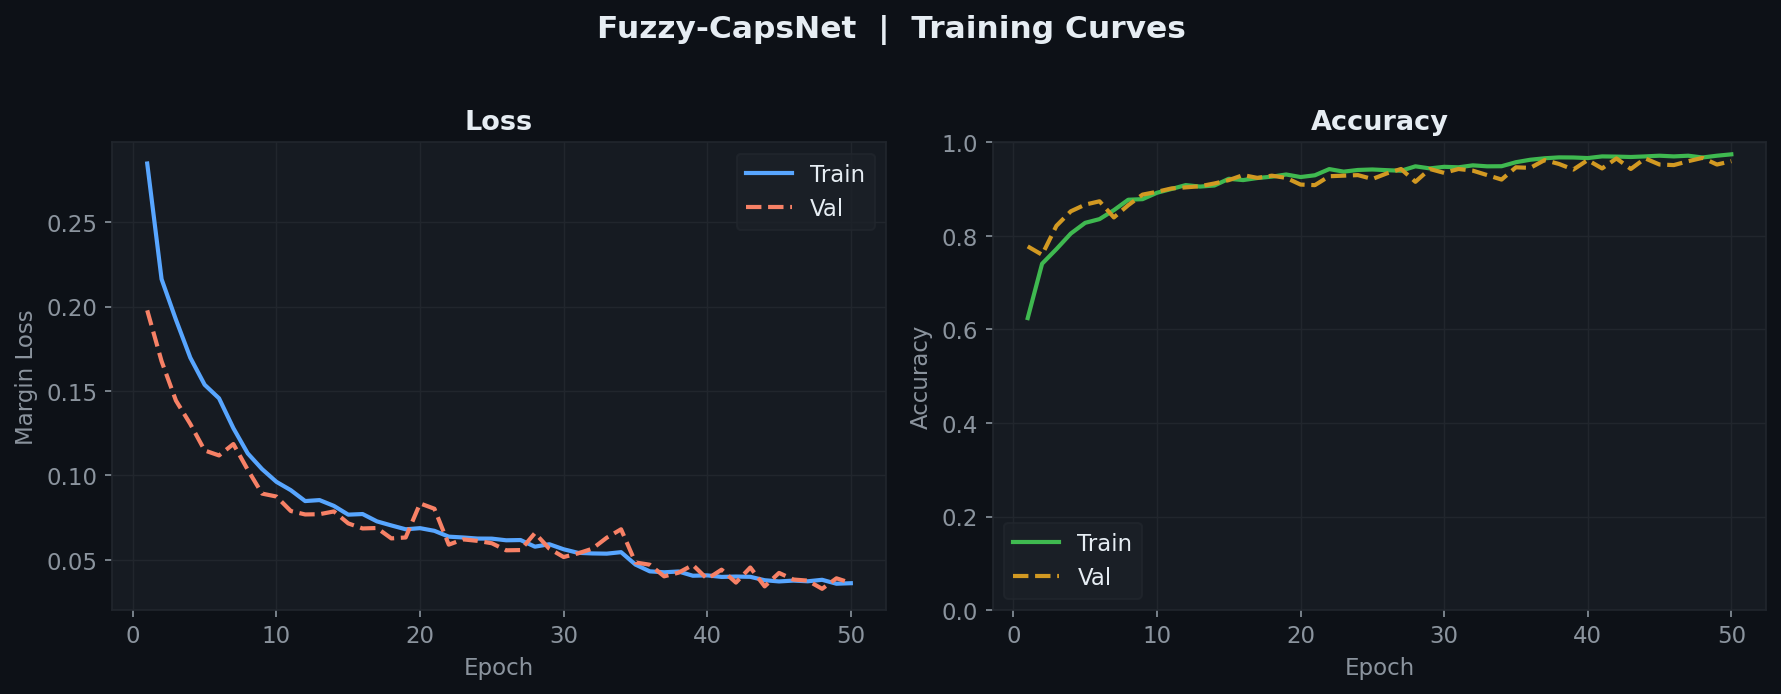

reliability_diagram.png


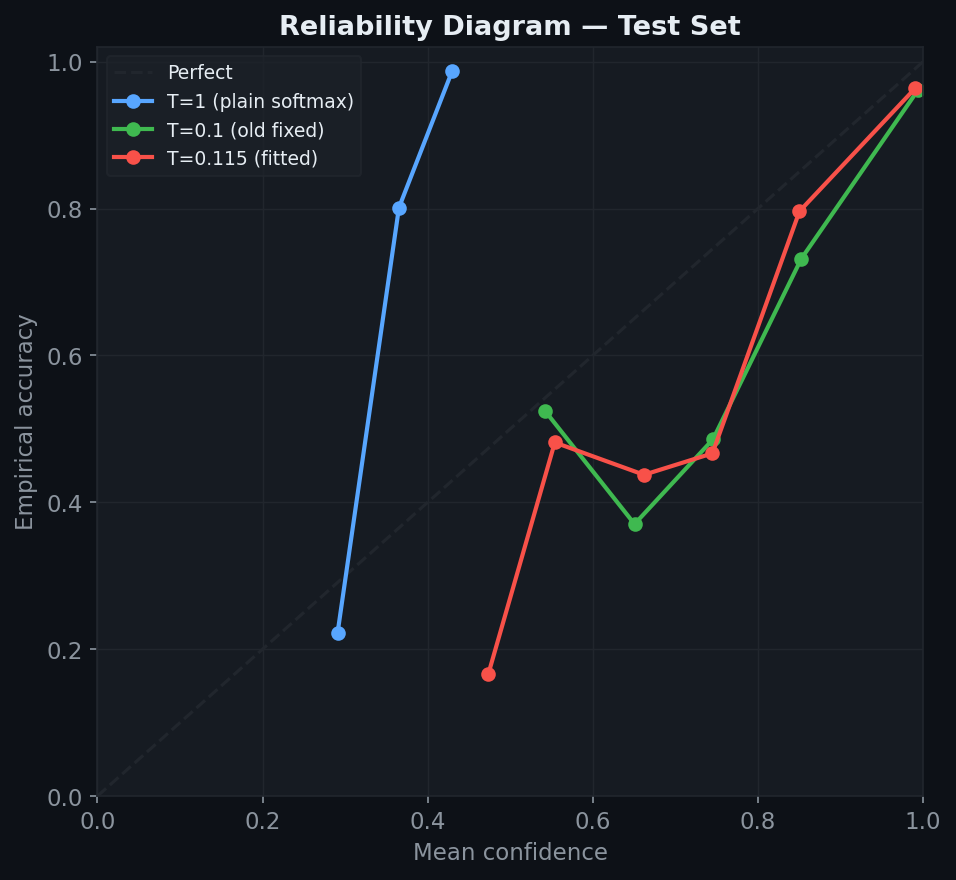

confusion_matrix.png


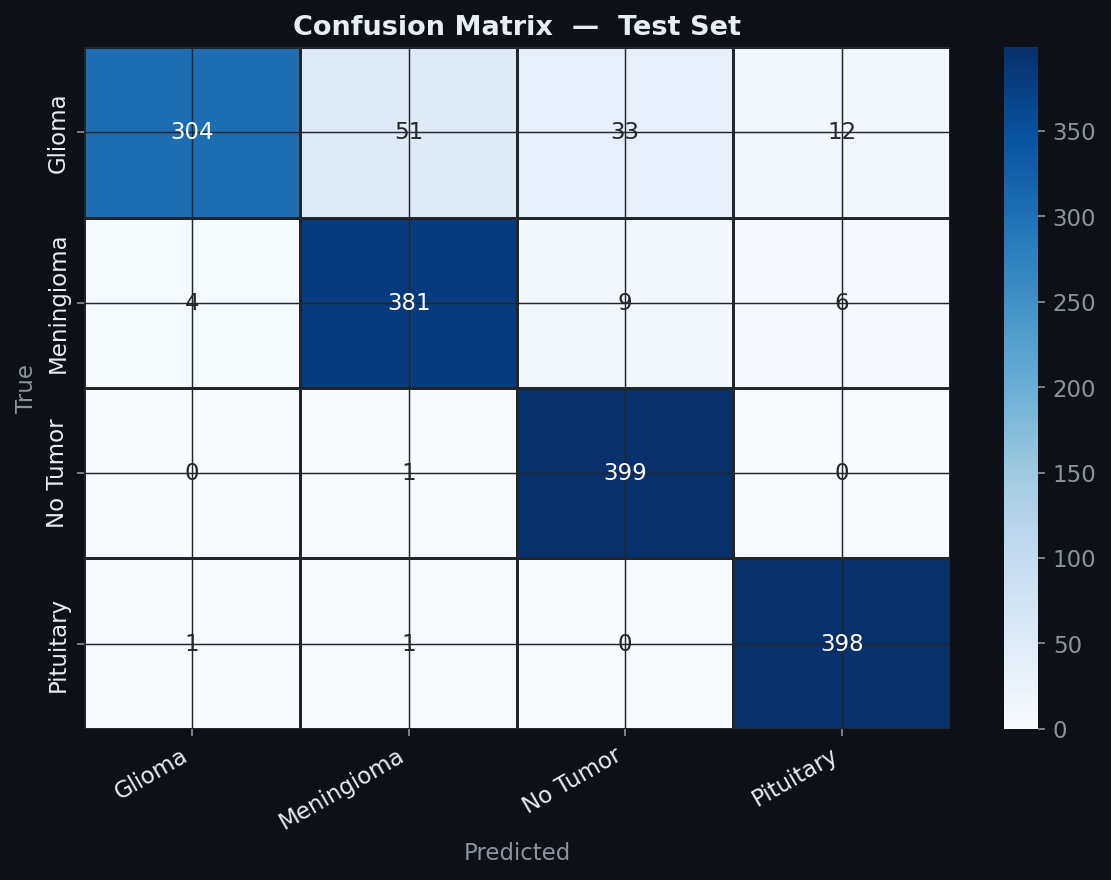

per_class_metrics.png


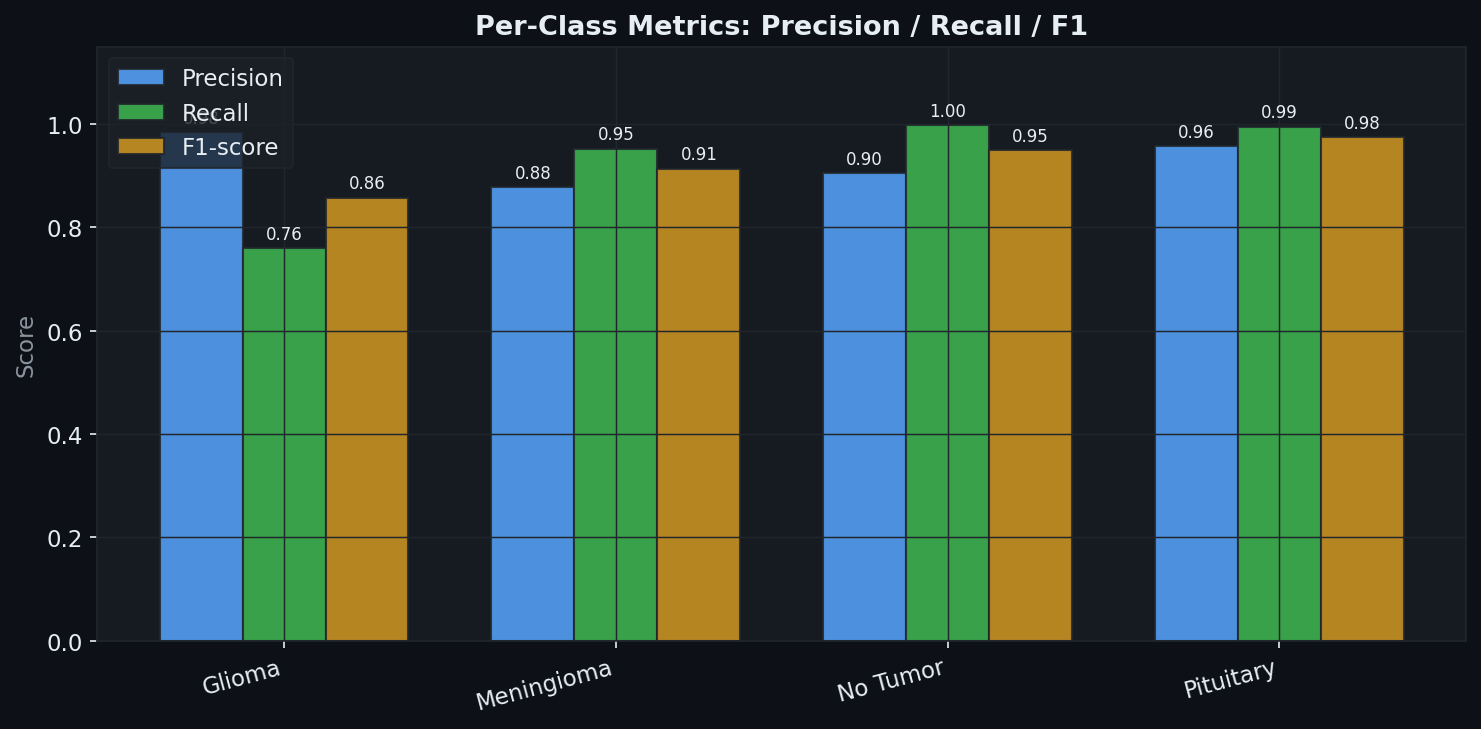

roc_auc.png


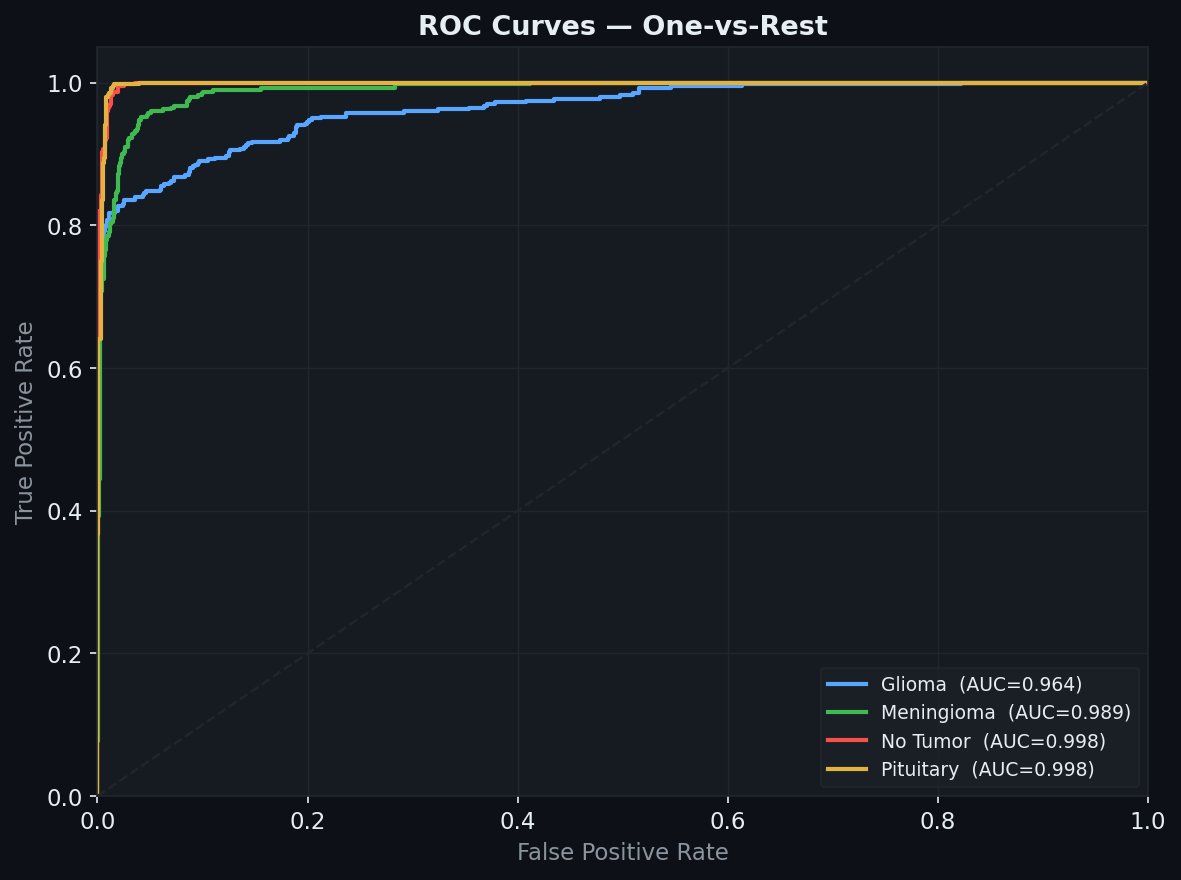

eval_output/06_confidence_distribution.png


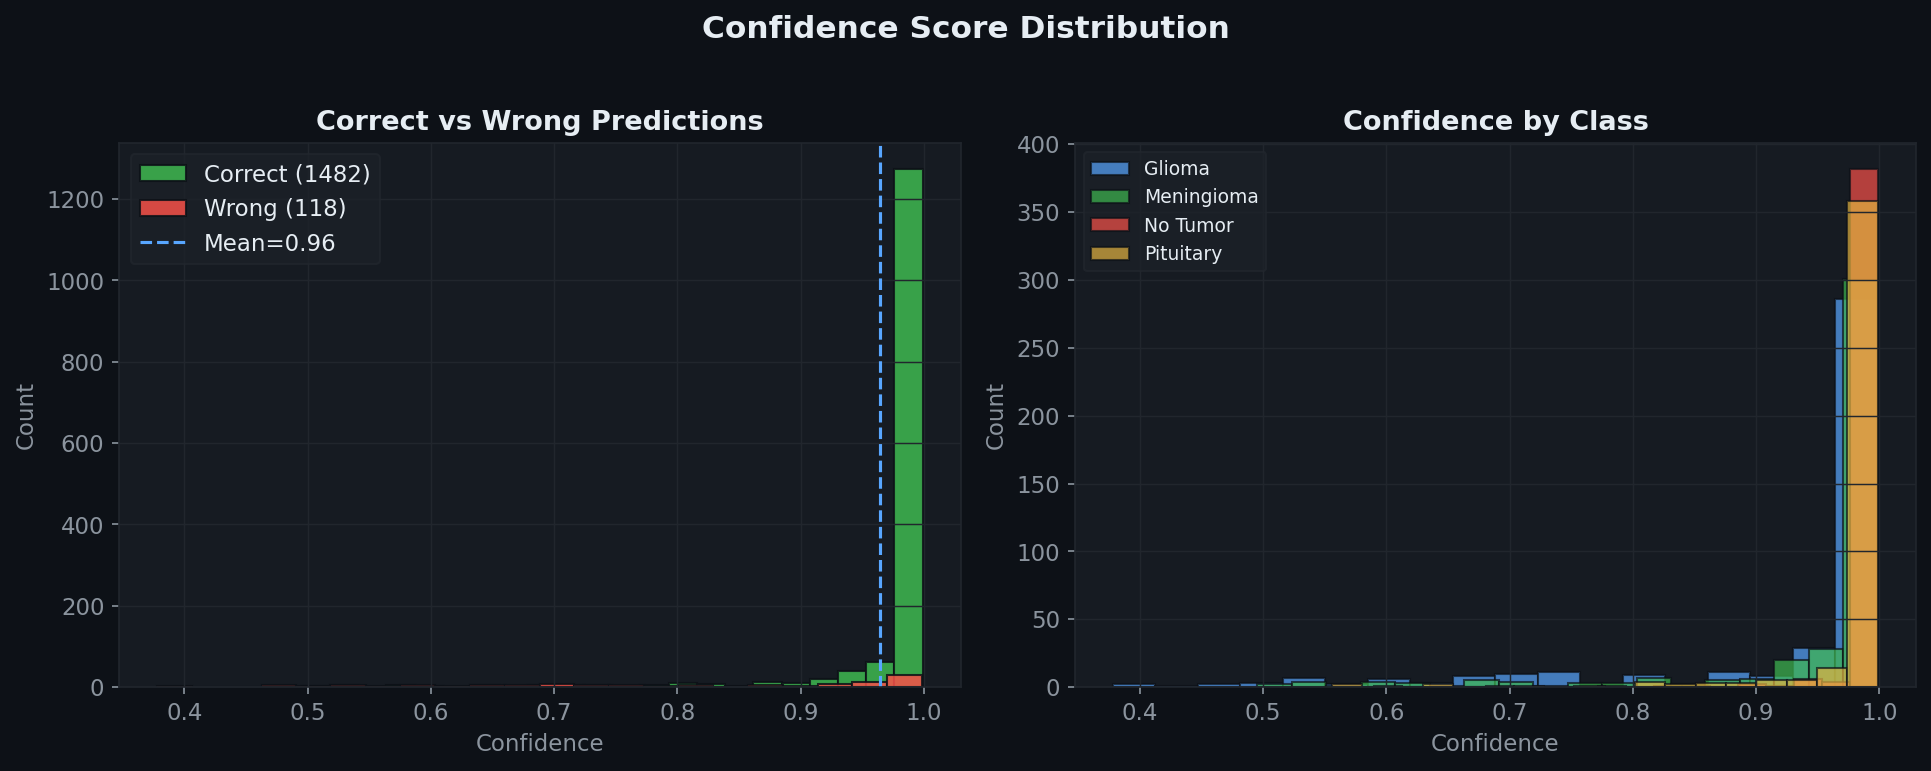

prediction_explanation.png


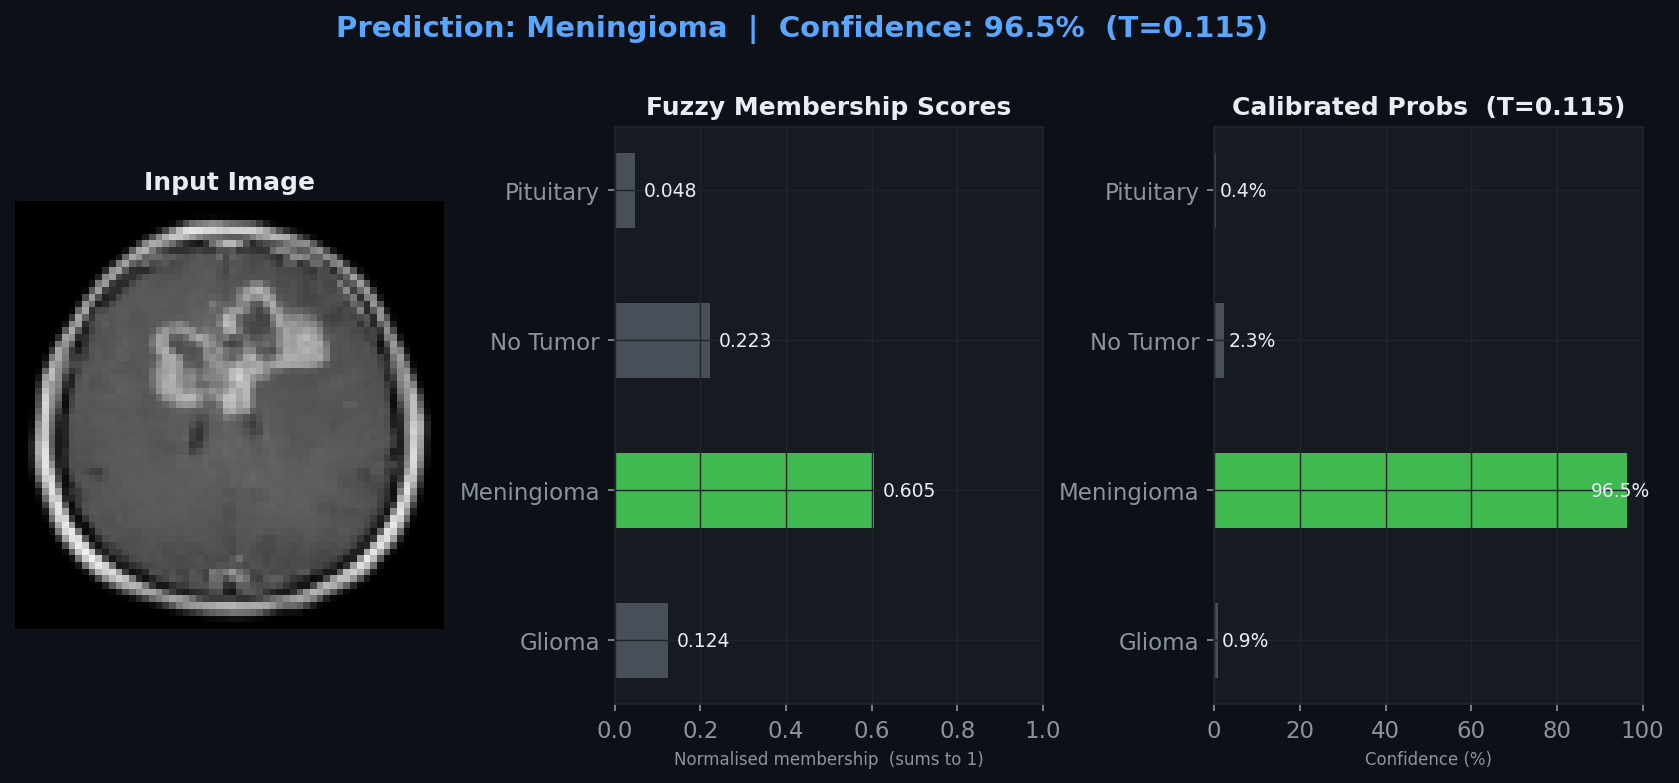


Everything is saved in: /content/drive/MyDrive/fuzzy_capsnet


In [16]:
from IPython.display import Image, display

for f in ['training_curves.png', 'reliability_diagram.png',
          'confusion_matrix.png', 'per_class_metrics.png', 'roc_auc.png',
          f'{EVAL_OUT_DIR}/06_confidence_distribution.png',
          'prediction_explanation.png']:
    if os.path.exists(f):
        print(f)
        display(Image(f))
print('\nEverything is saved in:', os.getcwd())
